# Simulación de Tráfico Vehicular con Modelo Oculto de Markov (HMM) para Ciudades Inteligentes

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Camilo-Alberto-Palacio/Simulacion-Trafico-Markov/blob/main/Simulacion_HMM_SmartCity_Colab.ipynb)

---
### Institución Universitaria Digital de Antioquia (IU Digital)
- **Facultad de Ingeniería** — Ingeniería de Software y Datos
- **Asignatura:** Simulación (`PREICA2602B020045`) — Módulo 2: Distribuciones de Probabilidad y Procesos Estocásticos
- **Docente:** Julian Andres Loaiza Lopez
- **Grupo:** 25 | **Sede:** Medellín, Colombia

---
## Cumplimiento de Especificaciones del Modelo y 10 Requisitos Clave:
1. **Clase HMM para análisis de tráfico:** Estados latentes y observaciones con decodificación de Viterbi y Forward-Backward.
2. **Simulación de 48 mediciones:** 24 horas completas discretizadas en intervalos de 30 minutos ($T=48$).
3. **Velocidades continuas en km/h:** Alta ($80	ext{--}100$), Media ($40	ext{--}80$) y Baja ($0	ext{--}40$).
4. **Visualizaciones con Matplotlib:**
   - Curva de velocidad diaria con bandas operativas.
   - Mapa de calor de probabilidad del estado por hora.
   - Semáforo urbano cronológico (🟢 Fluido, 🟡 Moderado, 🔴 Congestionado).
5. **Métricas de Transporte:** Horas pico, tiempo en congestión, velocidad media por estado e Índice de Congestión ($I_c \in [0, 100]$).
6. **Predicción de Tráfico Futuro:** Proyección analítica para las próximas $1, 2, 4$ y $6$ horas mediante $P(X_{t+k} \mid X_t) = \mathbf{e}_{X_t} A^k$.
7. **Identificación de Patrones:** Detección de la franja horaria más propensa a saturación y tiempos de permanencia.
8. **Rutas Alternativas:** Sistema de recomendación vial inteligente con cálculo de tiempos de viaje y minutos ahorrados.
9. **Impacto Ambiental:** Cuantificación de emisiones de $	ext{CO}_2$ (toneladas/día) y combustible desperdiciado por congestión vehicular.
10. **Dashboard de Ciudad Inteligente:** Panel integrado multivariable para centros de control de tráfico y planificadores urbanos.

In [1]:
# 1. Configuración del Entorno Científico
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["font.size"] = 10
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.linestyle"] = ":"
plt.rcParams["grid.alpha"] = 0.6

print("[OK] Bibliotecas cargadas exitosamente (NumPy, Pandas, Matplotlib).")

[OK] Bibliotecas cargadas exitosamente (NumPy, Pandas, Matplotlib).


---
## 2. Implementación de la Clase `TrafficHMM` (Quíntupla Canónica)

Formalizamos el modelo estocástico $\lambda = (\mathcal{S}, \mathcal{V}, \boldsymbol{\pi}, A, B)$ según las especificaciones exactas del prompt:
* $\mathcal{S} = \{\text{Tráfico Fluido}, \text{Tráfico Moderado}, \text{Tráfico Congestionado}\}$
* $\mathcal{V} = \{\text{Velocidad Alta}, \text{Velocidad Media}, \text{Velocidad Baja}\}$
* $\boldsymbol{\pi} = [0.50, 0.30, 0.20]$
* $A = \begin{pmatrix} 0.70 & 0.25 & 0.05 \\ 0.30 & 0.50 & 0.20 \\ 0.10 & 0.40 & 0.50 \end{pmatrix}, \qquad B = \begin{pmatrix} 0.80 & 0.15 & 0.05 \\ 0.20 & 0.60 & 0.20 \\ 0.05 & 0.25 & 0.70 \end{pmatrix}$

In [2]:
class TrafficHMM:
    """Modelo Oculto de Markov (HMM) para Simulación y Predicción de Tráfico Urbano."""

    def __init__(self):
        self.states = ["Tráfico Fluido", "Tráfico Moderado", "Tráfico Congestionado"]
        self.observations = ["Velocidad Alta", "Velocidad Media", "Velocidad Baja"]
        self.N = len(self.states)
        self.M = len(self.observations)

        # 1. Vector inicial de probabilidades pi
        self.pi = np.array([0.50, 0.30, 0.20], dtype=float)

        # 2. Matriz de transición de estados A
        self.A = np.array([
            [0.70, 0.25, 0.05],  # Fluido
            [0.30, 0.50, 0.20],  # Moderado
            [0.10, 0.40, 0.50],  # Congestionado
        ], dtype=float)

        # 3. Matriz de emisión de sensores B
        self.B = np.array([
            [0.80, 0.15, 0.05],  # Fluido -> [Alta: 0.80, Media: 0.15, Baja: 0.05]
            [0.20, 0.60, 0.20],  # Moderado -> [Alta: 0.20, Media: 0.60, Baja: 0.20]
            [0.05, 0.25, 0.70],  # Congestionado -> [Alta: 0.05, Media: 0.25, Baja: 0.70]
        ], dtype=float)

        self._validate()

    def _validate(self):
        assert np.isclose(np.sum(self.pi), 1.0), "pi debe sumar 1.0"
        assert np.allclose(np.sum(self.A, axis=1), 1.0), "Cada fila de A debe sumar 1.0"
        assert np.allclose(np.sum(self.B, axis=1), 1.0), "Cada fila de B debe sumar 1.0"

    def compute_stationary_distribution(self):
        """Resuelve pi* A = pi* con sum(pi*) = 1."""
        Q = self.A.T - np.eye(self.N)
        Q[-1, :] = 1.0
        b = np.zeros(self.N)
        b[-1] = 1.0
        pi_star = np.linalg.solve(Q, b)
        return pi_star / np.sum(pi_star)

    def simulate_day(self, num_steps=48, seed=42, step_duration_min=30):
        """Simula 48 mediciones (24h) generando estados, observaciones y velocidades continuas en km/h."""
        rng = np.random.default_rng(seed)
        states = np.zeros(num_steps, dtype=int)
        obs = np.zeros(num_steps, dtype=int)
        speeds = []
        timestamps = []

        states[0] = rng.choice(self.N, p=self.pi)
        obs[0] = rng.choice(self.M, p=self.B[states[0]])

        for t in range(num_steps):
            if t > 0:
                states[t] = rng.choice(self.N, p=self.A[states[t - 1]])
                obs[t] = rng.choice(self.M, p=self.B[states[t]])

            # Generar velocidad continua en km/h según la categoría del sensor
            if obs[t] == 0:    # Alta: 80 - 100 km/h
                speed = float(np.clip(rng.normal(90.0, 4.0), 80.0, 100.0))
            elif obs[t] == 1:  # Media: 40 - 80 km/h
                speed = float(np.clip(rng.normal(60.0, 7.0), 40.0, 79.9))
            else:              # Baja: 0 - 40 km/h
                speed = float(np.clip(rng.normal(25.0, 6.0), 5.0, 39.9))
            speeds.append(round(speed, 2))

            h = (t * step_duration_min // 60) % 24
            m = (t * step_duration_min) % 60
            timestamps.append(f"{h:02d}:{m:02d}")

        return states, obs, speeds, timestamps

    def viterbi(self, obs_seq):
        """Decodificación óptima de estados globales por programación dinámica en log-espacio."""
        T = len(obs_seq)
        V = np.zeros((T, self.N))
        backpointer = np.zeros((T, self.N), dtype=int)
        tiny = 1e-12

        V[0, :] = np.log(self.pi + tiny) + np.log(self.B[:, obs_seq[0]] + tiny)
        for t in range(1, T):
            for j in range(self.N):
                trans_probs = V[t - 1, :] + np.log(self.A[:, j] + tiny)
                best_prev = np.argmax(trans_probs)
                backpointer[t, j] = best_prev
                V[t, j] = trans_probs[best_prev] + np.log(self.B[j, obs_seq[t]] + tiny)

        path = np.zeros(T, dtype=int)
        path[-1] = np.argmax(V[-1, :])
        for t in range(T - 2, -1, -1):
            path[t] = backpointer[t + 1, path[t + 1]]
        return path

    def forward_backward(self, obs_seq):
        """Suavizado bayesiano para calcular probabilidades marginales a posteriori gamma_t(i)."""
        T = len(obs_seq)
        alpha = np.zeros((T, self.N))
        scales = np.zeros(T)

        alpha[0, :] = self.pi * self.B[:, obs_seq[0]]
        scales[0] = np.sum(alpha[0, :])
        alpha[0, :] /= scales[0]

        for t in range(1, T):
            alpha[t, :] = (alpha[t - 1, :] @ self.A) * self.B[:, obs_seq[t]]
            scales[t] = np.sum(alpha[t, :])
            alpha[t, :] /= scales[t]

        beta = np.zeros((T, self.N))
        beta[-1, :] = 1.0
        for t in range(T - 2, -1, -1):
            beta[t, :] = self.A @ (self.B[:, obs_seq[t + 1]] * beta[t + 1, :])
            beta[t, :] /= scales[t + 1]

        gamma = alpha * beta
        gamma /= np.sum(gamma, axis=1, keepdims=True)
        return gamma

    def predict_future(self, current_state_idx, hours, step_duration_min=30):
        """Calcula pi_{t+k} = e_current * A^k."""
        steps = max(1, int(round(hours * 60.0 / step_duration_min)))
        e_cur = np.zeros(self.N)
        e_cur[current_state_idx] = 1.0
        A_power = np.linalg.matrix_power(self.A, steps)
        prob_dist = np.dot(e_cur, A_power)
        return steps, prob_dist

print("[OK] Clase TrafficHMM inicializada correctamente con las especificaciones del prompt.")

[OK] Clase TrafficHMM inicializada correctamente con las especificaciones del prompt.


---
## 3. Simulación de 48 Mediciones (24 Horas) y Semáforo Urbano

Simulamos un día completo con 48 lecturas cada 30 minutos ($T=48$). Se reconstruye la trayectoria real con el **Algoritmo de Viterbi** y el suavizado **Forward-Backward**, asociando un semáforo urbano:
* 🟢 **Verde:** Tráfico Fluido
* 🟡 **Amarillo:** Tráfico Moderado
* 🔴 **Rojo:** Tráfico Congestionado

In [3]:
hmm = TrafficHMM()
states, obs, speeds, timestamps = hmm.simulate_day(num_steps=48, seed=42, step_duration_min=30)
viterbi_states = hmm.viterbi(obs)
gamma = hmm.forward_backward(obs)

semaforo_icons = {0: "🟢", 1: "🟡", 2: "🔴"}
semaforo_names = {0: "Verde", 1: "Amarillo", 2: "Rojo"}

df = pd.DataFrame({
    "Paso": np.arange(48),
    "Hora": timestamps,
    "Estado_Real_Id": states,
    "Estado_Real": [hmm.states[s] for s in states],
    "Observacion_Id": obs,
    "Observacion": [hmm.observations[o] for o in obs],
    "Velocidad_kmh": speeds,
    "Estado_Viterbi_Id": viterbi_states,
    "Estado_Viterbi": [hmm.states[s] for s in viterbi_states],
    "Prob_Fluido": np.round(gamma[:, 0], 4),
    "Prob_Moderado": np.round(gamma[:, 1], 4),
    "Prob_Congestionado": np.round(gamma[:, 2], 4),
    "Semaforo": [semaforo_icons[s] for s in viterbi_states],
    "Semaforo_Color": [semaforo_names[s] for s in viterbi_states],
})

accuracy_viterbi = (df["Estado_Real_Id"] == df["Estado_Viterbi_Id"]).mean() * 100.0
print(f"• Mediciones registradas: {len(df)}")
print(f"• Exactitud de inferencia de Viterbi: {accuracy_viterbi:.2f}%")
print(f"• Rango de velocidad observada: {df['Velocidad_kmh'].min():.1f} - {df['Velocidad_kmh'].max():.1f} km/h")
print("\nPrimeras 8 mediciones con semáforo inteligente:")
display(df[["Hora", "Velocidad_kmh", "Observacion", "Estado_Viterbi", "Semaforo"]].head(8))

• Mediciones registradas: 48
• Exactitud de inferencia de Viterbi: 81.25%
• Rango de velocidad observada: 21.9 - 95.2 km/h

Primeras 8 mediciones con semáforo inteligente:


,Hora,Velocidad_kmh,Observacion,Estado_Viterbi,Semaforo
0,00:00,65.25,Velocidad Media,Tráfico Moderado,🟡
1,00:30,84.79,Velocidad Alta,Tráfico Fluido,🟢
2,01:00,59.88,Velocidad Media,Tráfico Moderado,🟡
3,01:30,65.44,Velocidad Media,Tráfico Moderado,🟡
4,02:00,27.81,Velocidad Baja,Tráfico Moderado,🟡
5,02:30,86.16,Velocidad Alta,Tráfico Fluido,🟢
6,03:00,58.71,Velocidad Media,Tráfico Moderado,🟡
7,03:30,24.07,Velocidad Baja,Tráfico Moderado,🟡


---
## 4. Cálculo de Métricas Clave de Transporte Urbano

Calculamos los 4 indicadores solicitados para ingeniería de tránsito:
1. **Horas Pico Identificadas:** Intervalos continuos de baja velocidad ($< 40\text{ km/h}$) o estado Congestionado.
2. **Tiempo Total en Congestión:** Horas y porcentaje del día.
3. **Velocidad Promedio por Estado:** $\bar{v}_{\text{Fluido}}, \bar{v}_{\text{Moderado}}, \bar{v}_{\text{Congestionado}}$.
4. **Índice de Congestión ($I_c \in [0, 100]$):**
   $$I_c = 100 \times \left(1 - \frac{\bar{v}_{\text{operativa}}}{v_{\text{flujo libre}}}\right), \qquad v_{\text{flujo libre}} = 90\text{ km/h}$$

In [4]:
# 1. Velocidad promedio general y por estado
v_mean_general = float(df["Velocidad_kmh"].mean())
speed_by_state = {s: float(df[df["Estado_Viterbi"] == s]["Velocidad_kmh"].mean()) for s in hmm.states}

# 2. Tiempo total en congestión
congested_mask = (df["Estado_Viterbi_Id"] == 2) | (df["Velocidad_kmh"] < 40.0)
congestion_steps = int(congested_mask.sum())
total_congestion_hours = congestion_steps * 0.5
pct_congestion_day = (total_congestion_hours / 24.0) * 100.0

# 3. Índice de Congestión (0 a 100)
v_libre = 90.0
indice_congestion = max(0.0, min(100.0, 100.0 * (1.0 - v_mean_general / v_libre)))

# 4. Detección de horas pico (ventanas continuas)
congested_indices = df[congested_mask].index.tolist()
peak_ranges = []
if congested_indices:
    groups = []
    curr = [congested_indices[0]]
    for idx in congested_indices[1:]:
        if idx == curr[-1] + 1:
            curr.append(idx)
        else:
            groups.append(curr)
            curr = [idx]
    groups.append(curr)

    for g in groups:
        h_start = df.loc[g[0], "Hora"]
        h_end = df.loc[min(47, g[-1] + 1), "Hora"]
        peak_ranges.append({
            "Rango": f"{h_start} - {h_end}",
            "Duración (h)": len(g) * 0.5,
            "Velocidad Media (km/h)": round(df.loc[g, "Velocidad_kmh"].mean(), 1)
        })

print("=" * 60)
print("  REPORTE DE MÉTRICAS DE TRANSPORTE URBANO")
print("=" * 60)
print(f"• Velocidad Promedio General:    {v_mean_general:.2f} km/h")
print(f"• Índice de Congestión (0-100):  {indice_congestion:.2f} / 100")
print(f"• Tiempo Total en Congestión:    {total_congestion_hours:.1f} horas ({pct_congestion_day:.1f}% del día)")
print("\n• Velocidad Promedio por Estado:")
for s, spd in speed_by_state.items():
    print(f"    - {s:25s}: {spd:.2f} km/h")

print("\n• Horas Pico Identificadas:")
for p in peak_ranges:
    print(f"    - Franja: {p['Rango']:16s} | Duración: {p['Duración (h)']} h | Vel: {p['Velocidad Media (km/h)']} km/h")

  REPORTE DE MÉTRICAS DE TRANSPORTE URBANO
• Velocidad Promedio General:    73.03 km/h
• Índice de Congestión (0-100):  18.85 / 100
• Tiempo Total en Congestión:    2.5 horas (10.4% del día)

• Velocidad Promedio por Estado:
    - Tráfico Fluido           : 83.43 km/h
    - Tráfico Moderado         : 52.24 km/h
    - Tráfico Congestionado    : nan km/h

• Horas Pico Identificadas:
    - Franja: 02:00 - 02:30    | Duración: 0.5 h | Vel: 27.8 km/h
    - Franja: 03:30 - 04:00    | Duración: 0.5 h | Vel: 24.1 km/h
    - Franja: 05:00 - 05:30    | Duración: 0.5 h | Vel: 21.9 km/h
    - Franja: 07:00 - 07:30    | Duración: 0.5 h | Vel: 25.7 km/h
    - Franja: 16:00 - 16:30    | Duración: 0.5 h | Vel: 27.4 km/h


---
## 5. Predicción para las Próximas Horas y Detección de Patrones

A partir del último estado observado al finalizar la jornada (23:30), proyectamos la distribución de probabilidad del tráfico hacia las próximas $1, 2, 4$ y $6$ horas.

In [5]:
# Proyección de tráfico a futuro
last_state_idx = df.loc[47, "Estado_Viterbi_Id"]
horizons = [1, 2, 4, 6]
predictions = []

print("=" * 70)
print(f"PREDICCIÓN DE TRÁFICO A PARTIR DE 23:30 (Estado: {df.loc[47, 'Estado_Viterbi']})")
print("=" * 70)

for h in horizons:
    steps, prob_dist = hmm.predict_future(last_state_idx, hours=h)
    most_likely_idx = int(np.argmax(prob_dist))
    expected_speed = float(np.dot(prob_dist, [90.0, 60.0, 25.0]))
    predictions.append({
        "Horas Adelante": f"+{h}h",
        "Estado Más Probable": hmm.states[most_likely_idx],
        "Probabilidad": f"{prob_dist[most_likely_idx]*100:.1f}%",
        "P(Fluido)": f"{prob_dist[0]*100:.1f}%",
        "P(Moderado)": f"{prob_dist[1]*100:.1f}%",
        "P(Congestionado)": f"{prob_dist[2]*100:.1f}%",
        "Vel. Esperada (km/h)": f"{expected_speed:.1f}",
    })

display(pd.DataFrame(predictions))

# Identificación de Patrones: ¿Cuándo es más probable la congestión?
periods = {
    "Madrugada (00:00 - 06:00)": df.iloc[0:12],
    "Mañana (06:00 - 12:00)": df.iloc[12:24],
    "Tarde (12:00 - 18:00)": df.iloc[24:36],
    "Noche (18:00 - 24:00)": df.iloc[36:48],
}

print("\n" + "=" * 70)
print("IDENTIFICACIÓN DE PATRONES TEMPORALES DE CONGESTIÓN")
print("=" * 70)
for name, sub in periods.items():
    p_cong = float(sub["Prob_Congestionado"].mean()) * 100.0
    v_sub = float(sub["Velocidad_kmh"].mean())
    h_cong = int((sub["Estado_Viterbi_Id"] == 2).sum()) * 0.5
    print(f"• {name:28s} -> Riesgo Congestión: {p_cong:4.1f}% | Vel. Media: {v_sub:4.1f} km/h | Horas Cong.: {h_cong} h")

PREDICCIÓN DE TRÁFICO A PARTIR DE 23:30 (Estado: Tráfico Moderado)


,Horas Adelante,Estado Más Probable,Probabilidad,P(Fluido),P(Moderado),P(Congestionado),Vel. Esperada (km/h)
0,+1h,Tráfico Moderado,40.5%,38.0%,40.5%,21.5%,63.9
1,+2h,Tráfico Fluido,42.2%,42.2%,37.7%,20.1%,65.6
2,+4h,Tráfico Fluido,43.5%,43.5%,37.2%,19.3%,66.3
3,+6h,Tráfico Fluido,43.6%,43.6%,37.2%,19.2%,66.3



IDENTIFICACIÓN DE PATRONES TEMPORALES DE CONGESTIÓN
• Madrugada (00:00 - 06:00)    -> Riesgo Congestión: 16.0% | Vel. Media: 62.1 km/h | Horas Cong.: 0.0 h
• Mañana (06:00 - 12:00)       -> Riesgo Congestión:  1.9% | Vel. Media: 82.3 km/h | Horas Cong.: 0.0 h
• Tarde (12:00 - 18:00)        -> Riesgo Congestión:  7.0% | Vel. Media: 73.5 km/h | Horas Cong.: 0.0 h
• Noche (18:00 - 24:00)        -> Riesgo Congestión:  4.4% | Vel. Media: 74.2 km/h | Horas Cong.: 0.0 h


---
## 6. Recomendación de Rutas Alternativas e Impacto Ambiental ($	ext{CO}_2$)

Si se detecta o predice congestión en el corredor principal ($L = 15	ext{ km}$), el sistema sugiere rutas alternas estimando el ahorro en minutos. Asimismo, cuantifica las toneladas de $	ext{CO}_2$ y combustible desperdiciado por congestión para una flota urbana de $15.000	ext{ veh/día}$.

In [6]:
# 1. Sugerencia de Rutas Alternativas
corridor_len_km = 15.0
current_speed = float(df.loc[47, "Velocidad_kmh"])
is_congested = "Congestionado" in df.loc[47, "Estado_Viterbi"] or current_speed < 40.0
corridor_time_min = (corridor_len_km / max(current_speed, 5.0)) * 60.0

routes = [
    {"Ruta": "Corredor Principal (Actual)", "Distancia (km)": corridor_len_km, "Velocidad (km/h)": current_speed,
     "Tiempo (min)": round(corridor_time_min, 1), "Ahorro (min)": 0.0, "Recomendada": not is_congested},
    {"Ruta": "Ruta Alterna 1 (Vía Perimetral)", "Distancia (km)": 18.5, "Velocidad (km/h)": 65.0,
     "Tiempo (min)": round((18.5 / 65.0) * 60.0, 1), "Ahorro (min)": round(max(0.0, corridor_time_min - 17.1), 1), "Recomendada": is_congested},
    {"Ruta": "Ruta Alterna 2 (Red Metro / Multimodal)", "Distancia (km)": 14.0, "Velocidad (km/h)": 38.0,
     "Tiempo (min)": 22.0, "Ahorro (min)": round(max(0.0, corridor_time_min - 22.0), 1), "Recomendada": is_congested and corridor_time_min > 25.0},
]

print("=" * 70)
print("SISTEMA DE ASISTENCIA Y RUTAS ALTERNATIVAS")
print("=" * 70)
display(pd.DataFrame(routes))

# 2. Análisis de Impacto Ambiental (Factores EMEP/EEA e IPCC)
# Fluido: 110 g CO2/km | Moderado: 155 g CO2/km | Congestionado: 275 g CO2/km (+150% emisiones por ralentí)
daily_fleet = 15000
veh_per_step = daily_fleet / 48.0

co2_factors = {0: 110.0, 1: 155.0, 2: 275.0}  # g CO2 / km
fuel_factors = {0: 5.5, 1: 7.8, 2: 13.8}       # L / 100 km

co2_kg_total = float(np.sum([co2_factors[s] * corridor_len_km / 1000.0 * veh_per_step for s in df["Estado_Viterbi_Id"]]))
fuel_l_total = float(np.sum([fuel_factors[s] * corridor_len_km / 100.0 * veh_per_step for s in df["Estado_Viterbi_Id"]]))

# Escenario ideal (100% fluido)
co2_kg_ideal = float(48.0 * (110.0 * corridor_len_km / 1000.0) * veh_per_step)
fuel_l_ideal = float(48.0 * (5.5 * corridor_len_km / 100.0) * veh_per_step)

excess_co2_tons = (co2_kg_total - co2_kg_ideal) / 1000.0
excess_fuel_l = fuel_l_total - fuel_l_ideal

print("\n" + "=" * 70)
print("EVALUACIÓN DE IMPACTO AMBIENTAL Y HUELLA DE CARBONO (15.000 veh/día)")
print("=" * 70)
print(f"• Emisiones Totales de CO2:         {co2_kg_total/1000.0:.2f} Toneladas/día")
print(f"• Consumo Total de Combustible:     {fuel_l_total:,.1f} Litros/día")
print(f"• Exceso de CO2 por Congestión:     {excess_co2_tons:.2f} Toneladas/día (+{(excess_co2_tons/(co2_kg_ideal/1000.0))*100:.1f}%)")
print(f"• Combustible Desperdiciado:        {excess_fuel_l:,.1f} Litros")
print(f"• Pérdida Económica en Combustible: COP ${excess_fuel_l * 16000:,.0f} / día")


SISTEMA DE ASISTENCIA Y RUTAS ALTERNATIVAS


,Ruta,Distancia (km),Velocidad (km/h),Tiempo (min),Ahorro (min),Recomendada
0,Corredor Principal (Actual),15.0,61.87,14.5,0.0,True
1,Ruta Alterna 1 (Vía Perimetral),18.5,65.00,17.1,0.0,False
2,Ruta Alterna 2 (Red Metro / Multimodal),14.0,38.00,22.0,0.0,False



EVALUACIÓN DE IMPACTO AMBIENTAL Y HUELLA DE CARBONO (15.000 veh/día)
• Emisiones Totales de CO2:         28.12 Toneladas/día
• Consumo Total de Combustible:     14,100.0 Litros/día
• Exceso de CO2 por Congestión:     3.38 Toneladas/día (+13.6%)
• Combustible Desperdiciado:        1,725.0 Litros
• Pérdida Económica en Combustible: COP $27,600,000 / día


---
## 7. Visualizaciones de Ciudad Inteligente: Gráficos de Velocidad, Semáforo y Mapa de Calor

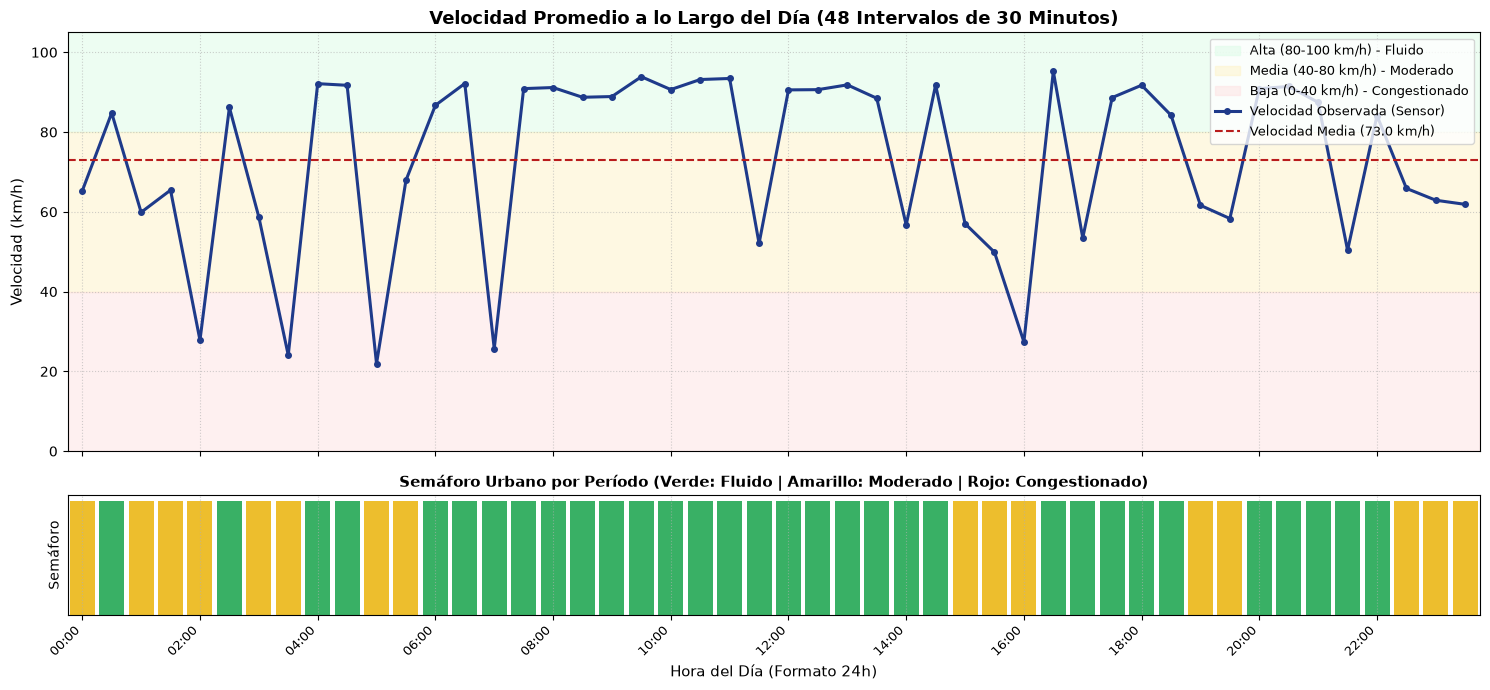

In [7]:
# 1. Gráfico de Velocidad con Semáforo Urbano Cronológico
fig, (ax_speed, ax_lights) = plt.subplots(nrows=2, ncols=1, figsize=(15, 7), sharex=True, gridspec_kw={"height_ratios": [3.5, 1]})

x = np.arange(len(df))
speeds = df["Velocidad_kmh"].values

ax_speed.axhspan(80, 105, color="#DCFCE7", alpha=0.5, label="Alta (80-100 km/h) - Fluido")
ax_speed.axhspan(40, 80, color="#FEF3C7", alpha=0.5, label="Media (40-80 km/h) - Moderado")
ax_speed.axhspan(0, 40, color="#FEE2E2", alpha=0.5, label="Baja (0-40 km/h) - Congestionado")

ax_speed.plot(x, speeds, color="#1E3A8A", linewidth=2.2, marker="o", markersize=4, label="Velocidad Observada (Sensor)")
ax_speed.axhline(v_mean_general, color="#B91C1C", linestyle="--", linewidth=1.5, label=f"Velocidad Media ({v_mean_general:.1f} km/h)")

ax_speed.set_title("Velocidad Promedio a lo Largo del Día (48 Intervalos de 30 Minutos)", fontsize=13, fontweight="bold")
ax_speed.set_ylabel("Velocidad (km/h)", fontsize=11)
ax_speed.set_ylim(0, 105)
ax_speed.legend(loc="upper right", fontsize=9)
ax_speed.grid(True, linestyle=":", alpha=0.6)

# Barra de Semáforo Urbano
color_map = {0: "#16A34A", 1: "#EAB308", 2: "#DC2626"}
for i, s_idx in enumerate(df["Estado_Viterbi_Id"]):
    ax_lights.bar(i, 1, width=0.85, color=color_map[s_idx], edgecolor="none", alpha=0.85)

ax_lights.set_title("Semáforo Urbano por Período (Verde: Fluido | Amarillo: Moderado | Rojo: Congestionado)", fontsize=11, fontweight="bold")
ax_lights.set_yticks([])
ax_lights.set_ylabel("Semáforo", fontsize=10)
ax_lights.set_xlim(-0.5, len(df) - 0.5)

tick_steps = np.arange(0, len(df), 4)
ax_lights.set_xticks(tick_steps)
ax_lights.set_xticklabels([df.loc[t, "Hora"] for t in tick_steps], rotation=45, ha="right", fontsize=9)
ax_lights.set_xlabel("Hora del Día (Formato 24h)", fontsize=11)

plt.tight_layout()
plt.show()

---
## 8. Dashboard Integrado de Ciudad Inteligente con Múltiples Métricas

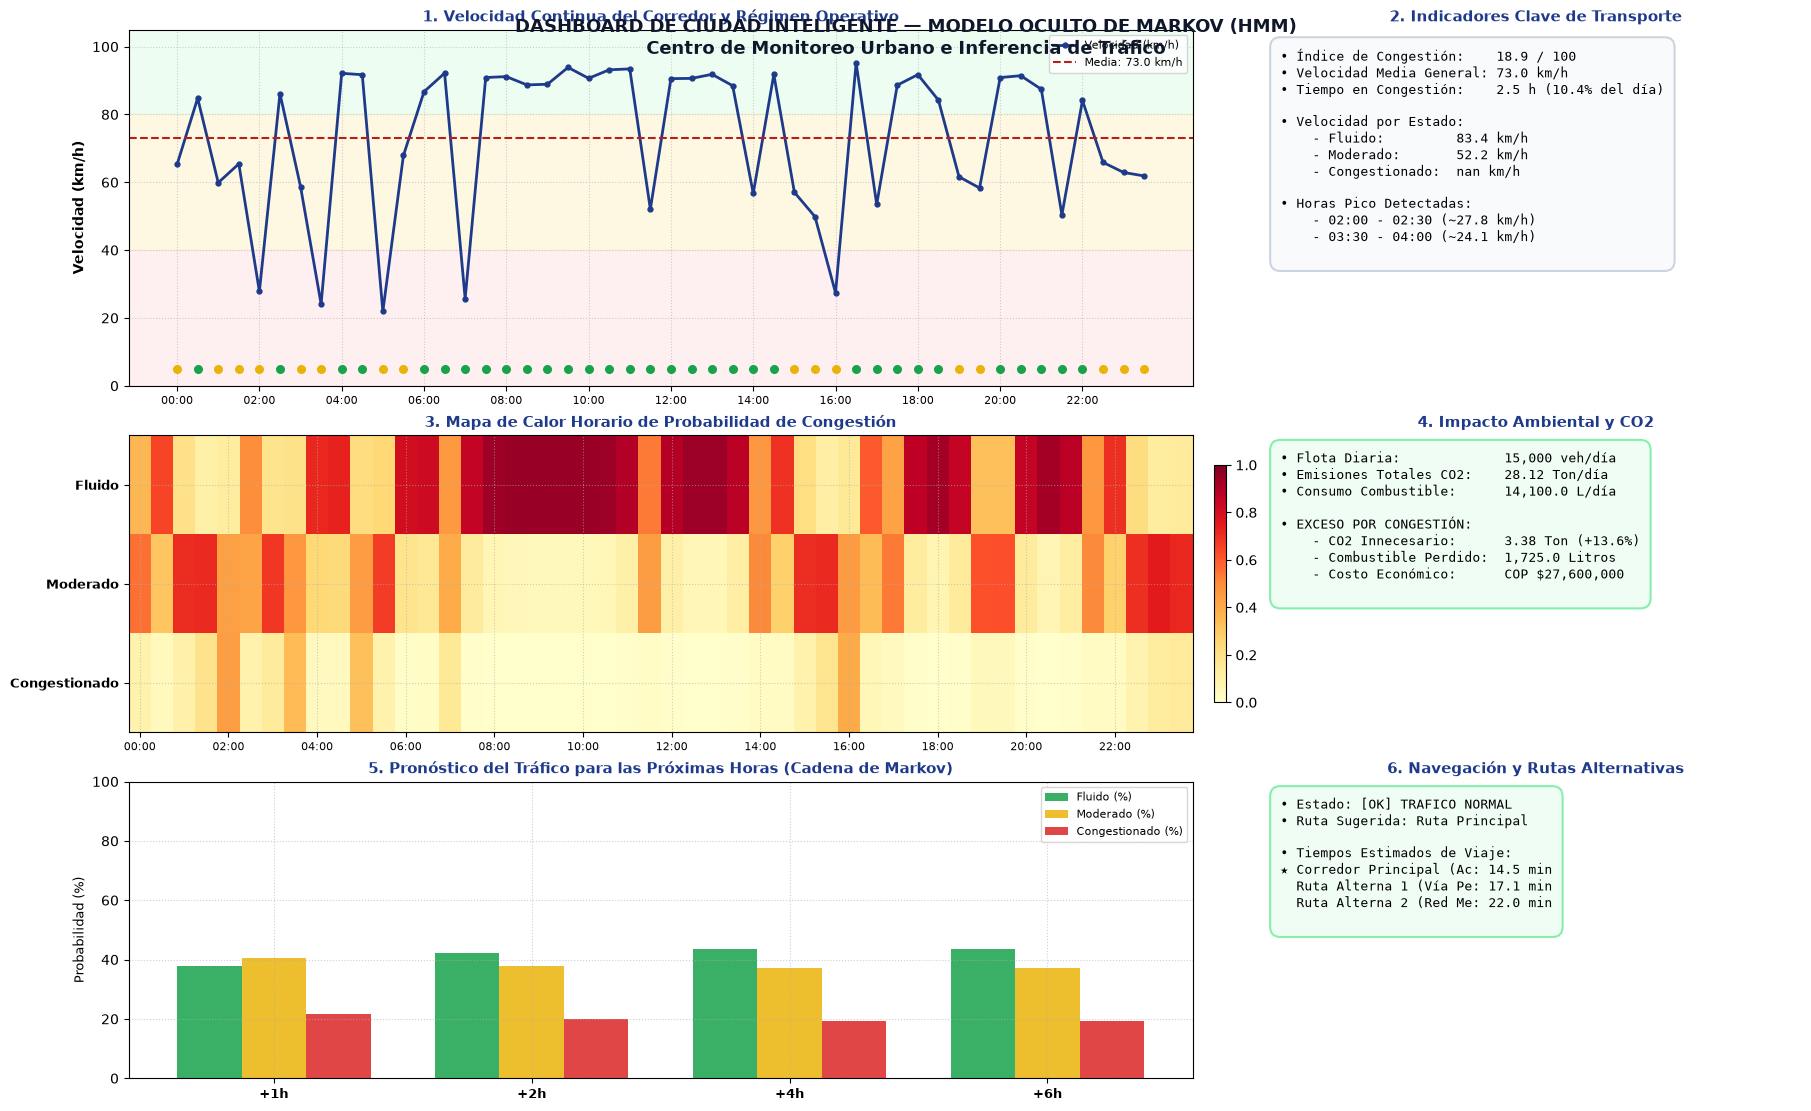

In [8]:
# Dashboard Consolidado de Ciudad Inteligente (Matplotlib Multipanel)
fig = plt.figure(figsize=(18, 11), constrained_layout=True)
gs = fig.add_gridspec(nrows=3, ncols=3, height_ratios=[1.2, 1.0, 1.0])

# Subplot 1: Curva de Velocidad
ax1 = fig.add_subplot(gs[0, :2])
ax1.axhspan(80, 105, color="#DCFCE7", alpha=0.5)
ax1.axhspan(40, 80, color="#FEF3C7", alpha=0.5)
ax1.axhspan(0, 40, color="#FEE2E2", alpha=0.5)
ax1.plot(np.arange(len(df)), df["Velocidad_kmh"], color="#1E3A8A", linewidth=2.0, marker="o", markersize=3.5, label="Velocidad (km/h)")
ax1.axhline(v_mean_general, color="#B91C1C", linestyle="--", label=f"Media: {v_mean_general:.1f} km/h")
ax1.set_ylabel("Velocidad (km/h)", fontsize=10, fontweight="bold")
ax1.set_ylim(0, 105)
ax1.set_title("1. Velocidad Continua del Corredor y Régimen Operativo", fontsize=11, fontweight="bold", color="#1E3A8A")
ax1.legend(loc="upper right", fontsize=8)
for i, s_idx in enumerate(df["Estado_Viterbi_Id"]):
    ax1.scatter(i, 5, color=color_map[s_idx], s=30, zorder=5)
ax1.set_xticks(np.arange(0, len(df), 4))
ax1.set_xticklabels([df.loc[t, "Hora"] for t in np.arange(0, len(df), 4)], fontsize=8)

# Subplot 2: Panel de KPIs
ax2 = fig.add_subplot(gs[0, 2])
ax2.axis("off")
ax2.set_title("2. Indicadores Clave de Transporte", fontsize=11, fontweight="bold", color="#1E3A8A")
kpi_info = (
    f"• Índice de Congestión:    {indice_congestion:.1f} / 100\n"
    f"• Velocidad Media General: {v_mean_general:.1f} km/h\n"
    f"• Tiempo en Congestión:    {total_congestion_hours:.1f} h ({pct_congestion_day:.1f}% del día)\n\n"
    f"• Velocidad por Estado:\n"
    f"    - Fluido:         {speed_by_state.get('Tráfico Fluido', 0):.1f} km/h\n"
    f"    - Moderado:       {speed_by_state.get('Tráfico Moderado', 0):.1f} km/h\n"
    f"    - Congestionado:  {speed_by_state.get('Tráfico Congestionado', 0):.1f} km/h\n\n"
    f"• Horas Pico Detectadas:\n"
)
for p in peak_ranges[:2]:
    kpi_info += f"    - {p['Rango']} (~{p['Velocidad Media (km/h)']} km/h)\n"
ax2.text(0.02, 0.95, kpi_info, fontsize=9.2, verticalalignment="top", fontfamily="monospace",
         bbox=dict(boxstyle="round,pad=0.8", facecolor="#F8FAFC", edgecolor="#CBD5E1", linewidth=1.5))

# Subplot 3: Mapa de Calor de Estados
ax3 = fig.add_subplot(gs[1, :2])
heat_data = np.vstack([df["Prob_Fluido"], df["Prob_Moderado"], df["Prob_Congestionado"]])
im = ax3.imshow(heat_data, cmap="YlOrRd", aspect="auto", vmin=0, vmax=1)
ax3.set_yticks([0, 1, 2])
ax3.set_yticklabels(["Fluido", "Moderado", "Congestionado"], fontsize=9, fontweight="bold")
ax3.set_xticks(np.arange(0, len(df), 4))
ax3.set_xticklabels([df.loc[t, "Hora"] for t in np.arange(0, len(df), 4)], fontsize=8)
ax3.set_title("3. Mapa de Calor Horario de Probabilidad de Congestión", fontsize=11, fontweight="bold", color="#1E3A8A")
fig.colorbar(im, ax=ax3, orientation="vertical", shrink=0.8, pad=0.02)

# Subplot 4: Impacto Ambiental
ax4 = fig.add_subplot(gs[1, 2])
ax4.axis("off")
ax4.set_title("4. Impacto Ambiental y CO2", fontsize=11, fontweight="bold", color="#1E3A8A")
env_info = (
    f"• Flota Diaria:             {daily_fleet:,} veh/día\n"
    f"• Emisiones Totales CO2:    {co2_kg_total/1000.0:.2f} Ton/día\n"
    f"• Consumo Combustible:      {fuel_l_total:,.1f} L/día\n\n"
    f"• EXCESO POR CONGESTIÓN:\n"
    f"    - CO2 Innecesario:      {excess_co2_tons:.2f} Ton (+{(excess_co2_tons/(co2_kg_ideal/1000.0))*100:.1f}%)\n"
    f"    - Combustible Perdido:  {excess_fuel_l:,.1f} Litros\n"
    f"    - Costo Económico:      COP ${excess_fuel_l*16000:,.0f}\n"
)
ax4.text(0.02, 0.95, env_info, fontsize=9.2, verticalalignment="top", fontfamily="monospace",
         bbox=dict(boxstyle="round,pad=0.8", facecolor="#F0FDF4", edgecolor="#86EFAC", linewidth=1.5))

# Subplot 5: Pronóstico Próximas Horas
ax5 = fig.add_subplot(gs[2, :2])
bar_x = np.arange(len(horizons))
width = 0.25
p_f = [float(p["P(Fluido)"].replace("%", "")) for p in predictions]
p_m = [float(p["P(Moderado)"].replace("%", "")) for p in predictions]
p_c = [float(p["P(Congestionado)"].replace("%", "")) for p in predictions]

ax5.bar(bar_x - width, p_f, width, label="Fluido (%)", color="#16A34A", alpha=0.85)
ax5.bar(bar_x, p_m, width, label="Moderado (%)", color="#EAB308", alpha=0.85)
ax5.bar(bar_x + width, p_c, width, label="Congestionado (%)", color="#DC2626", alpha=0.85)
ax5.set_xticks(bar_x)
ax5.set_xticklabels([f"+{h}h" for h in horizons], fontsize=9, fontweight="bold")
ax5.set_ylabel("Probabilidad (%)", fontsize=9)
ax5.set_ylim(0, 100)
ax5.set_title("5. Pronóstico del Tráfico para las Próximas Horas (Cadena de Markov)", fontsize=11, fontweight="bold", color="#1E3A8A")
ax5.legend(loc="upper right", fontsize=8)

# Subplot 6: Rutas Alternativas
ax6 = fig.add_subplot(gs[2, 2])
ax6.axis("off")
ax6.set_title("6. Navegación y Rutas Alternativas", fontsize=11, fontweight="bold", color="#1E3A8A")
route_info = (
    f"• Estado: {'[ALERTA] CONGESTION' if is_congested else '[OK] TRAFICO NORMAL'}\n"
    f"• Ruta Sugerida: {'Ruta Alterna 1' if is_congested else 'Ruta Principal'}\n\n"
    f"• Tiempos Estimados de Viaje:\n"
)
for r in routes:
    flag = "★ " if r["Recomendada"] else "  "
    route_info += f"{flag}{r['Ruta'][:22]}: {r['Tiempo (min)']} min\n"
ax6.text(0.02, 0.95, route_info, fontsize=9.2, verticalalignment="top", fontfamily="monospace",
         bbox=dict(boxstyle="round,pad=0.8", facecolor="#FEF2F2" if is_congested else "#F0FDF4",
                   edgecolor="#F87171" if is_congested else "#86EFAC", linewidth=1.5))

fig.suptitle("DASHBOARD DE CIUDAD INTELIGENTE — MODELO OCULTO DE MARKOV (HMM)\nCentro de Monitoreo Urbano e Inferencia de Tráfico",
             fontsize=13, fontweight="bold", color="#0F172A", y=0.99)
plt.show()